## Лабораторная 01. "Анализ аудио: от волновой формы к признакам ASR"

**Выполнила:** Иванова М.К.  
**Проверил:** Романенко А.Н.

## 0. Импорты

In [47]:
import sys
import librosa
import numpy as np
import pandas as pd
import soundfile as sf
import librosa.display
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import Image, display, Markdown, Audio

In [43]:
DATA_DIR = Path("data/wav")
OUT_DIR = Path("outputs")

## Часть A — Генерирация и проверка аудиофайлов

### Вопросы:

1) **У какого файла, по вашему ожиданию, будет самая высокая RMS-энергия?**

RMS - это среднеквадратичная амплитуда 
Самая высокая RMS будет у `noisy_speech_like.wav`. Будут появляться случайные колебания, шум заполнит паузы, энергия сигнала растет.

2) **В каком файле, по вашему ожиданию, искажение волновой формы будет наиболее заметным?**  

Самое заметное искажение волновой формы будет наблюдаться у `clipped_speech_like.wav`. Клиппинг срезает все отсчёты выше порога, поэтому вместо пиков будут видны усеченные вершины - горизонтальные плато на одном уровне (что бросается в глаза). У `noisy_speech_like.wav` тоже форма изменится, но общая структура останется прежней.  

3) **В каком файле, по вашему ожиданию, спектральные переходы будут наиболее размытыми?**  

Самые размытые спектральные переходы будут видны у `reverberant_speech_like.wav`. Реверберация - это свёртка сигнала с импульсной характеристикой помещения. Появляется многократное отражение звука от поверхностей, а, следовательно, на спектрограмме будут видны смазанные переходы, форманты не будут четкими.

In [3]:
files = [
    "clean_speech_like.wav",
    "noisy_speech_like.wav",
    "reverberant_speech_like.wav",
    "clipped_speech_like.wav",
    "speed_perturbed_speech_like.wav",
]

for name in files:
    audio, sr = sf.read(DATA_DIR / name)
    display(Markdown(f"**{name}** — {len(audio)/sr:.2f}с, sr={sr}, peak={abs(audio).max():.3f}"))
    display(Audio(audio, rate=sr))

**clean_speech_like.wav** — 5.20с, sr=16000, peak=0.780

**noisy_speech_like.wav** — 5.20с, sr=16000, peak=0.920

**reverberant_speech_like.wav** — 5.20с, sr=16000, peak=0.880

**clipped_speech_like.wav** — 5.20с, sr=16000, peak=0.340

**speed_perturbed_speech_like.wav** — 4.52с, sr=16000, peak=0.780

## Часть B — Статистика аудио

In [4]:
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

summary = pd.read_csv(OUT_DIR / "audio_summary.csv")
summary

,filename,sample_rate_hz,duration_s,num_samples,peak_amplitude,rms,silence_fraction,clipping_fraction
0,clean_speech_like.wav,16000,5.200,83200,0.780029,0.250151,0.388930,0.000024
1,clipped_speech_like.wav,16000,5.200,83200,0.340027,0.245213,0.298690,0.463798
2,noisy_speech_like.wav,16000,5.200,83200,0.920013,0.265441,0.077200,0.000012
3,reverberant_speech_like.wav,16000,5.200,83200,0.880005,0.216411,0.385096,0.000108
4,speed_perturbed_speech_like.wav,16000,4.522,72348,0.780029,0.250186,0.389244,0.000014


## Часть B — Статистика аудио

| Файл | Длительность, с | Пик | RMS | Доля тишины | Доля клиппинга |
|---|---:|---:|---:|---:|---:|
| clean | 5.200 | 0.780 | 0.250 | 0.3889 | 0.000024 |
| noisy | 5.200 | 0.920 | 0.265 | 0.0772 | 0.000012 |
| reverberant | 5.200 | 0.880 | 0.216 | 0.3851 | 0.000108 |
| clipped | 5.200 | 0.340 | 0.245 | 0.2987 | 0.463798 |
| speed_perturbed | 4.522 | 0.780 | 0.250 | 0.3892 | 0.000014 |

Вопросы:

1) У какого файла доля клиппинга ненулевая или необычно высокая? Почему?

Самая высокая доля клиппинга у `clipped_speech_like.wav`. При генерации сигнал усилили в 2.4 раза и обрезали по порогу ±0.34, поэтому часть отсчётов упирается в этот уровень и превращается в плоские плато.

2) У какого файла самая короткая длительность? Почему?

Самая короткая длительность у `speed_perturbed_speech_like.wav` - сигнала с увеличенной скоростью, что связано с тем, что при увеличении скорости в 1.15 раза, длительность пропорционально уменьшается и тот же сигнал проигрывается быстрее в 1.15 раза: 5.20 / 1.15 = 4.52 с.

3) Почему доля тишины может быть важна для ASR на длинных записях?

На длинных записях по паузам работает VAD, который разделяет речь и паузы. Если доля тишины мала (как у noisy: 0.077 вместо типичных 0.39), шум заполняет паузы, и VAD может не найти границы реплик, принять шум за речь. В таком случае модель может вставить "лишнее слово" или исказить существующее.

## Часть C — Волновая форма

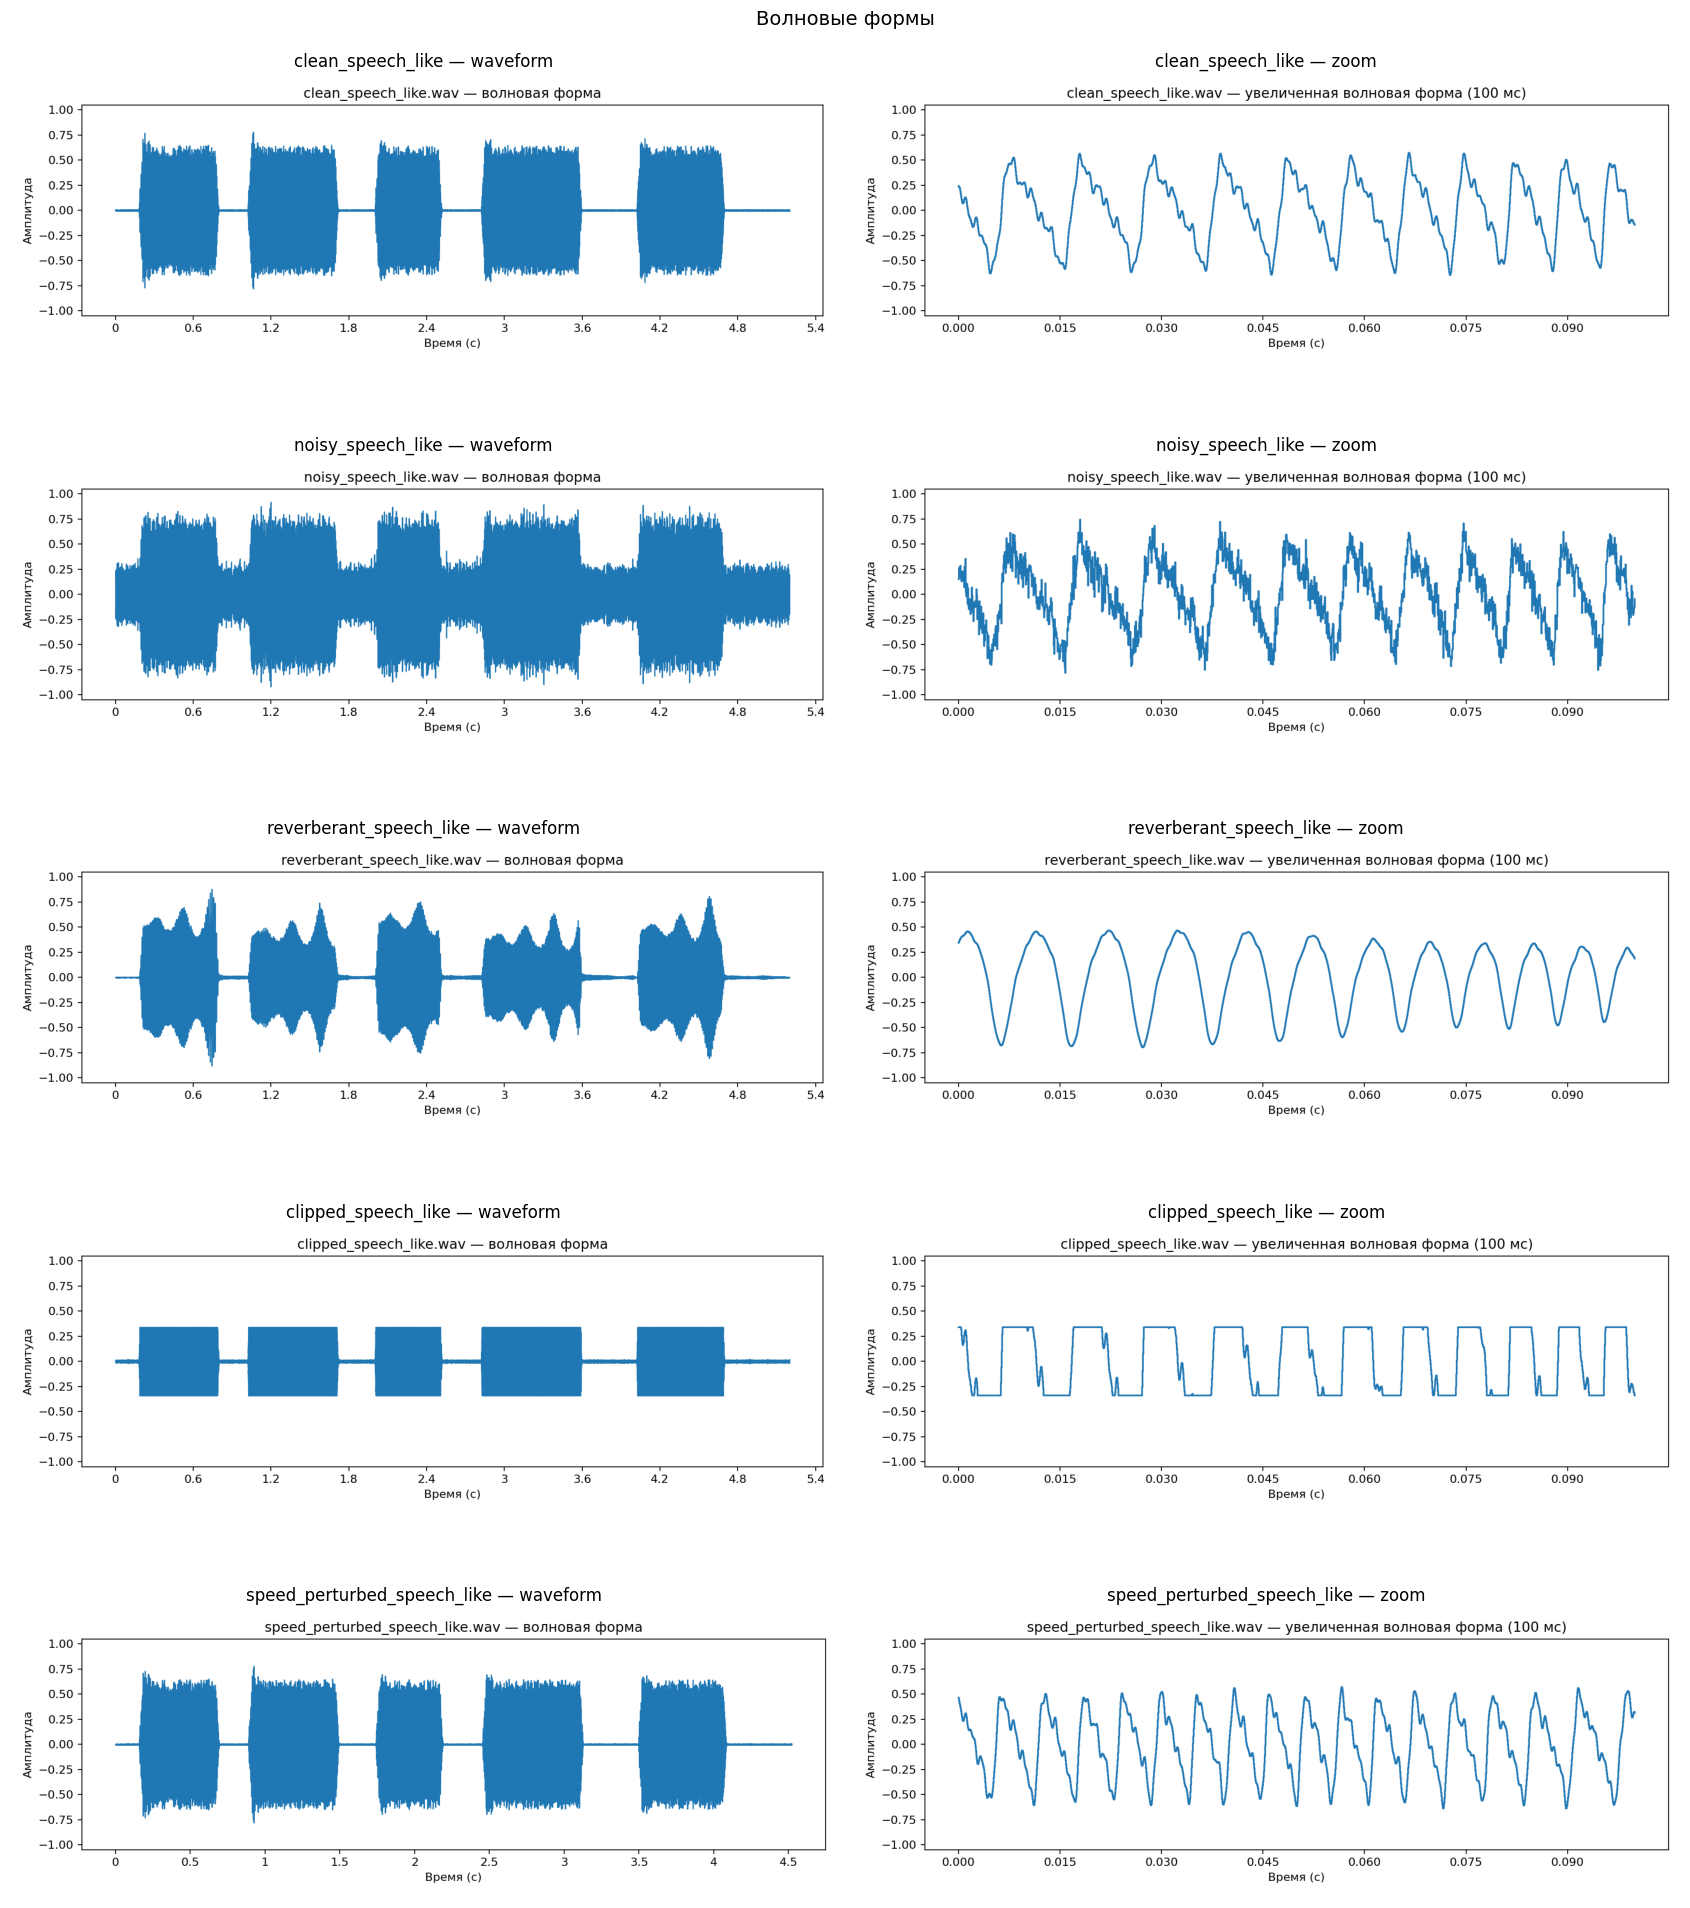

In [ ]:
files = [
    "clean_speech_like",
    "noisy_speech_like",
    "reverberant_speech_like",
    "clipped_speech_like",
    "speed_perturbed_speech_like",
]

fig, axes = plt.subplots(len(files), 2, figsize=(17, 4 * len(files)))

for row, stem in enumerate(files):
    img_full = mpimg.imread(OUT_DIR / f"{stem}_waveform.png")
    img_zoom = mpimg.imread(OUT_DIR / f"{stem}_waveform_zoom.png")
    
    axes[row, 0].imshow(img_full)
    axes[row, 0].set_title(f"{stem} — waveform")
    axes[row, 0].axis("off")
    
    axes[row, 1].imshow(img_zoom)
    axes[row, 1].set_title(f"{stem} — zoom")
    axes[row, 1].axis("off")

fig.suptitle("Волновые формы", fontsize=14)
fig.tight_layout()
plt.show()

Вопросы:

1) Какое искажение легче всего увидеть на волновой форме?

Клиппинг. На волновой форме будут видны горизонтальные плато на фиксированном уровне, что выдает клиппинг. В естественной речи таких участков быть не может. Шум и реверберация тоже искажают форму, но эти искажения выглядят естественнее и их проще спутать с нормальной речью.

2) Как выглядит клиппинг?

Плоские горизонтальные плато на одном заданном уровне. Сигнал упирается в порог и не может пойти выше или ниже. Пик клиппированного сигнала намного ниже, чем у остальных.

3) Почему одной амплитуды может быть недостаточно, чтобы понять содержание речи?

Волновая форма показывает только амплитуду во времени. По ней не определить фонетическую структура: какие звуки произнесены, где гласные и согласные, какие форманты. Для различения речи важна частотная составляющая. Поэтому для понимания содержания нужны спектрограммы, log-Mel, MFCC.

## Часть D — Лог-спектрограмма STFT

Спектрограмма STFT показывает, как энергия частот меняется во времени.



**clean_speech_like_stft_spectrogram.png**

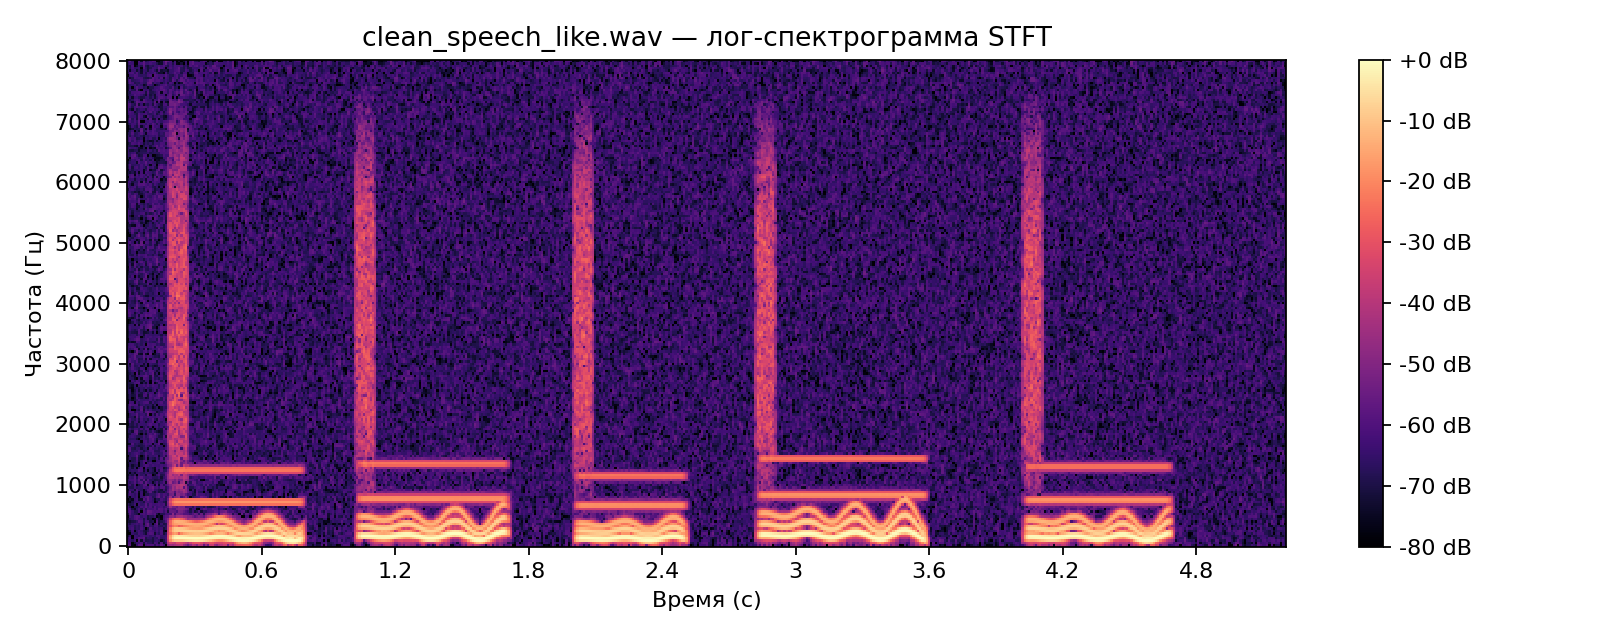

**noisy_speech_like_stft_spectrogram.png**

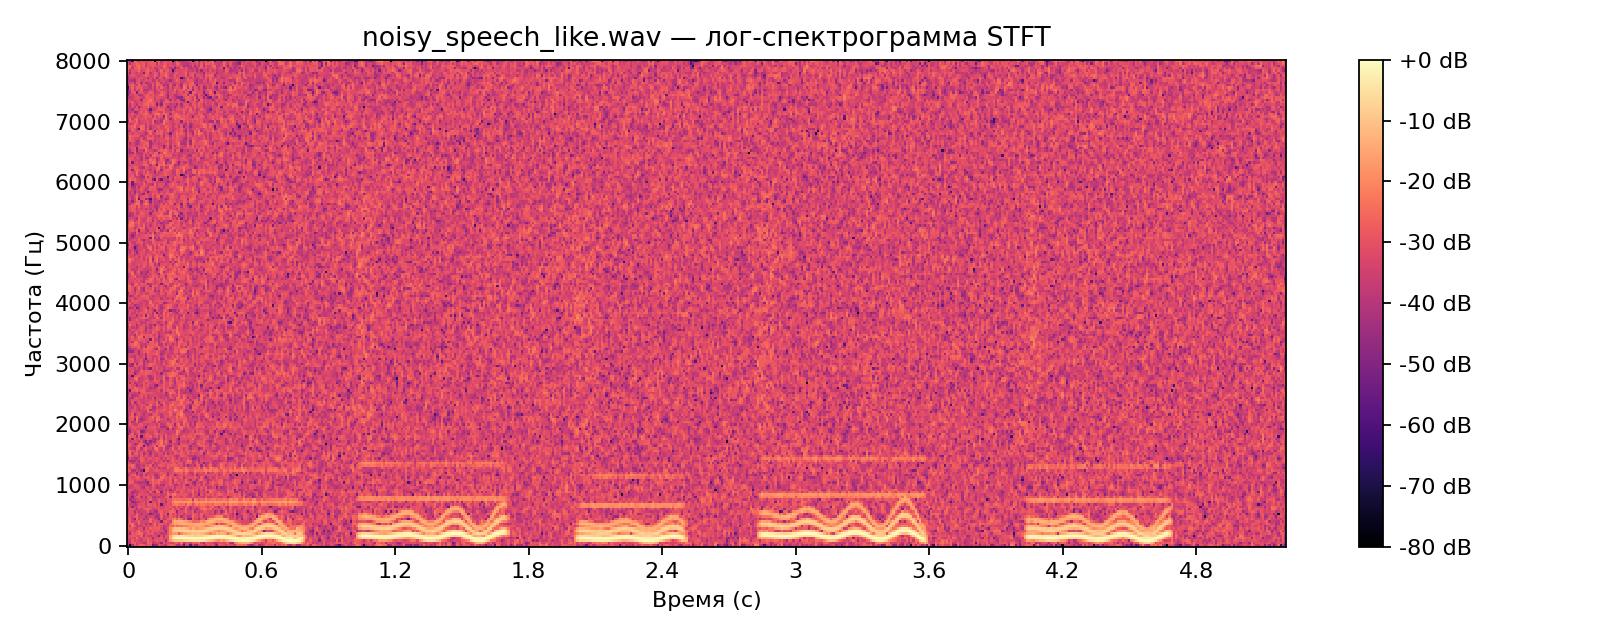

**reverberant_speech_like_stft_spectrogram.png**

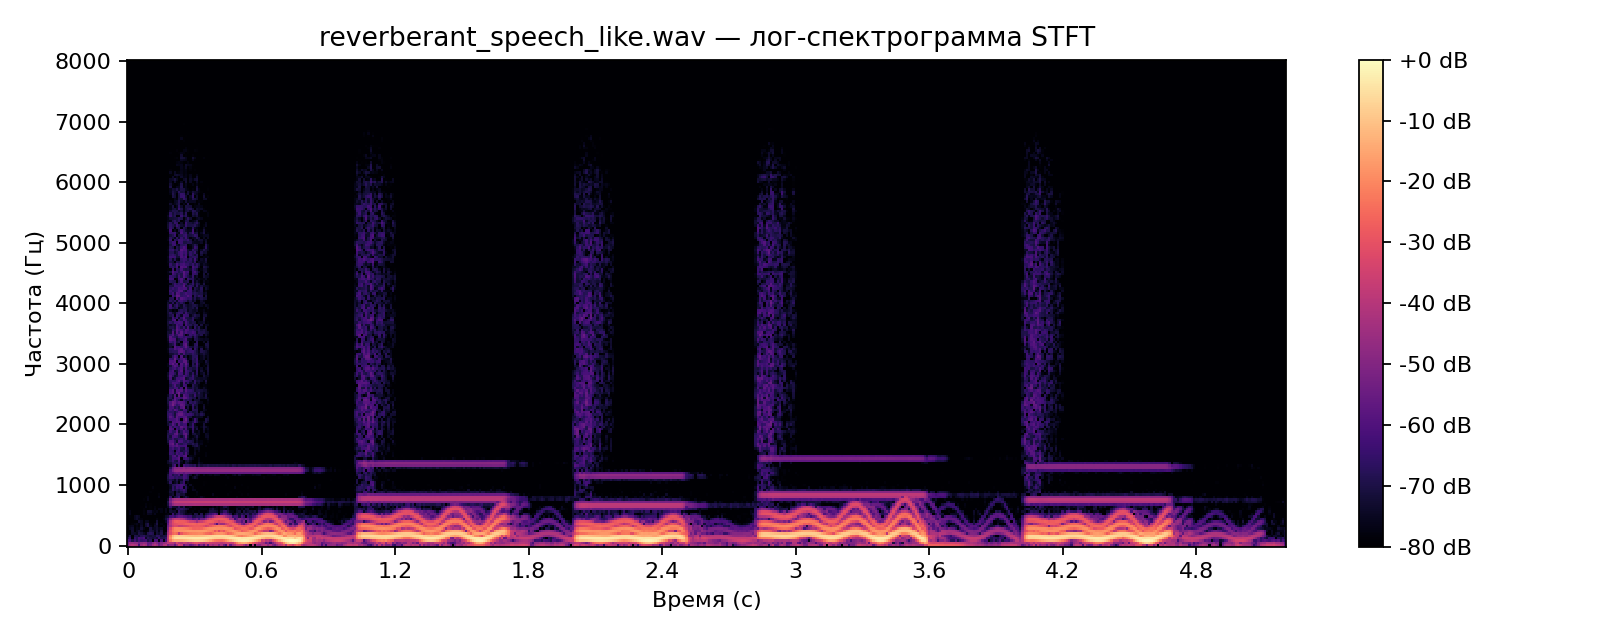

**clipped_speech_like_stft_spectrogram.png**

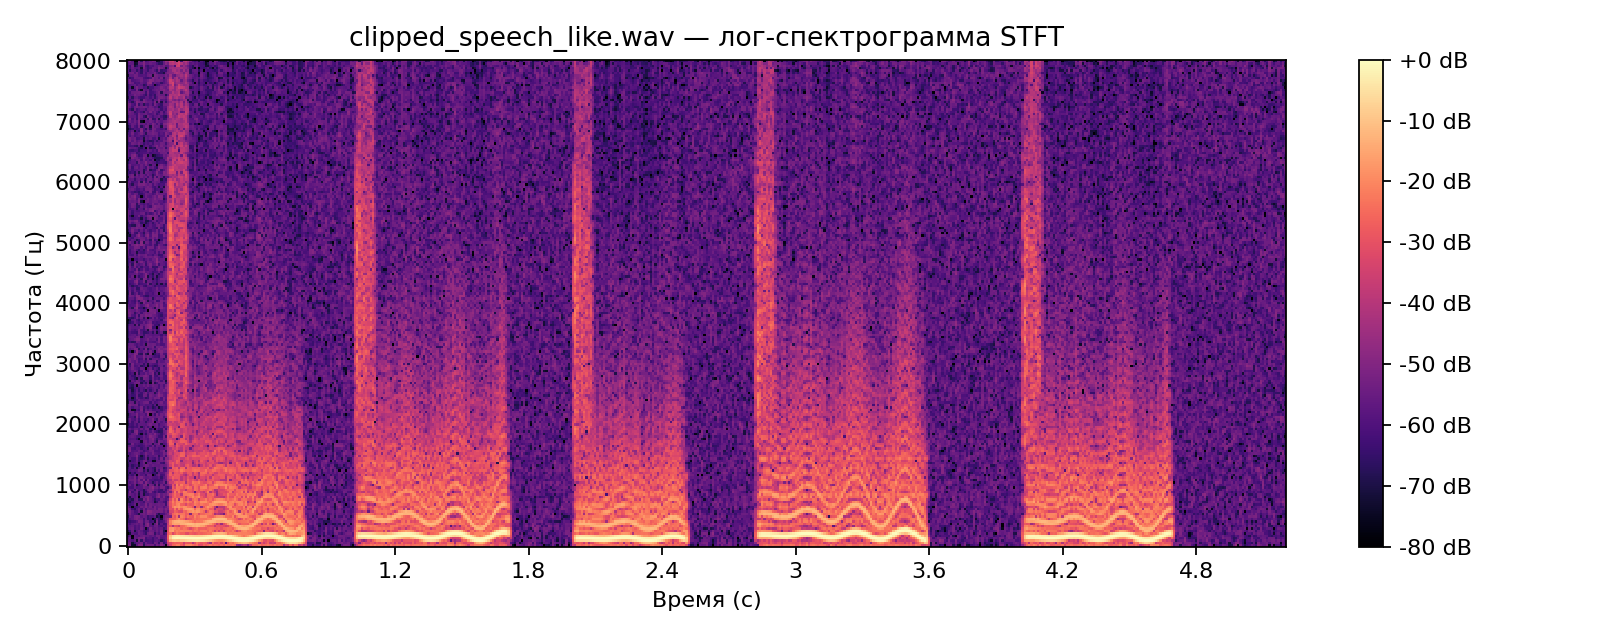

**speed_perturbed_speech_like_stft_spectrogram.png**

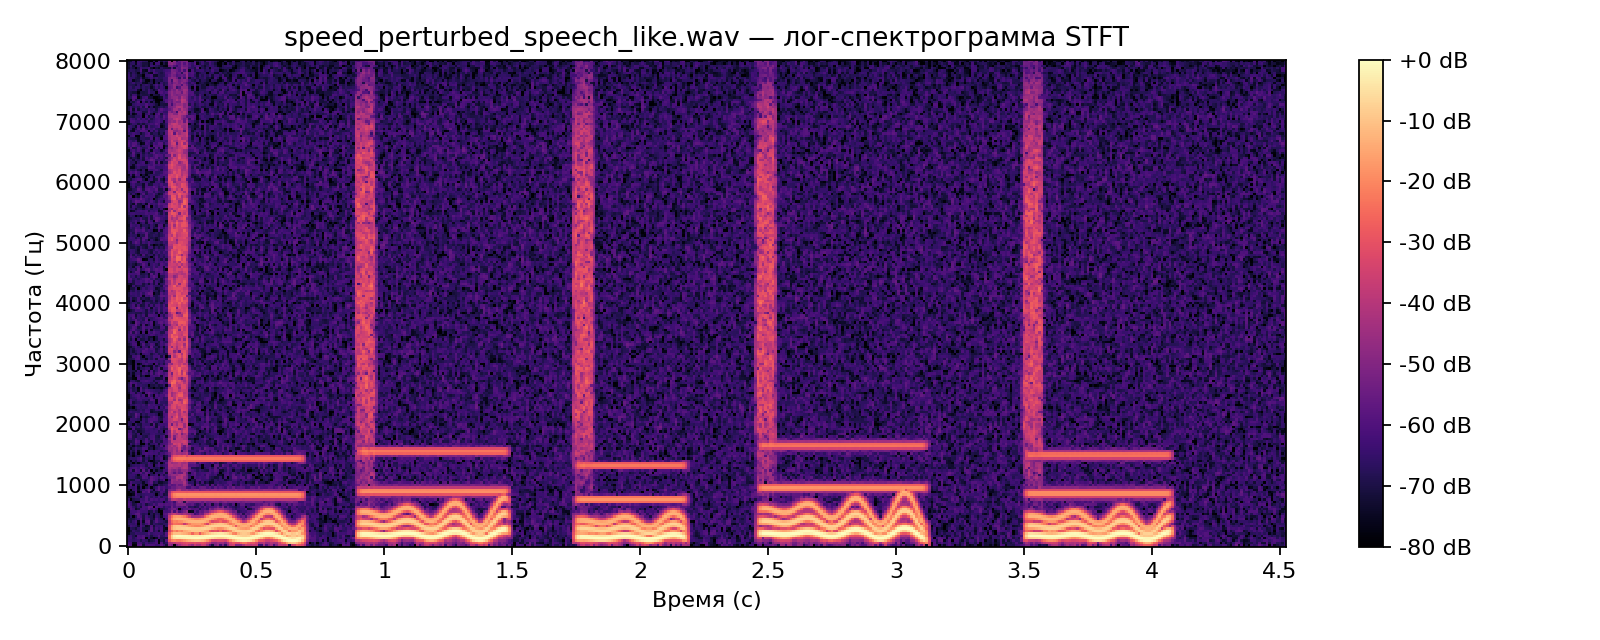

In [6]:
stft_files = [
    "clean_speech_like_stft_spectrogram.png",
    "noisy_speech_like_stft_spectrogram.png",
    "reverberant_speech_like_stft_spectrogram.png",
    "clipped_speech_like_stft_spectrogram.png",
    "speed_perturbed_speech_like_stft_spectrogram.png",
]

for name in stft_files:
    display(Markdown(f"**{name}**"))
    display(Image(OUT_DIR / name))

Вопросы:

1) В каком файле больше всего широкополосной высокочастотной энергии?

Больше всего широкополосной высокочастотной энергии в `noisy_speech_like.wav`. Добавление шума искажает спектрограмму таким образом, что на всей спектрограмме энергия увеличивается, что проявляется в высветлении графика. В связи с этим сам полезный сигнал становится трудноразличим, поскольку энергия в паузах, заполненных шумом, приближается к энергии полезного сигнала.

2) Как реверберация меняет time-frequency паттерн?

Спектрограмма теряет четкость во времени. Из-за наложения звуков друг на друга и на собственные отражения горизонтальные гармоники становятся размытыми, смазываются границы речевых сегментов, в паузах ( особенно это видно в нижней части спектрограммы) появляется заполнение (цвет на спектрограмме светлеет из-за роста энергии). При поздней реверберации речь может потерять разборчивость.

3) Почему шум может вызывать замены или удаления в ASR?

Шум накладывается на речевые сегменты и покрывает тишину. Это меняет частотный состав сигнала, который необходим для точного определения звуков и участков "речь/не речь" VAD-ом. Поэтому модель может принять шум за речь и ложно распознать или некорректно определить речевое содержание сигнала. Кроме того, с шумом легко смешиваются и путаются глухие щелевые согласные с низкой энергией.

## Часть E — Log-Mel-спектрограмма

Log-Mel признаки сжимают частотную информацию в перцептивно мотивированные полосы и широко используются в нейросетевом ASR.

**clean_speech_like_log_mel.png**

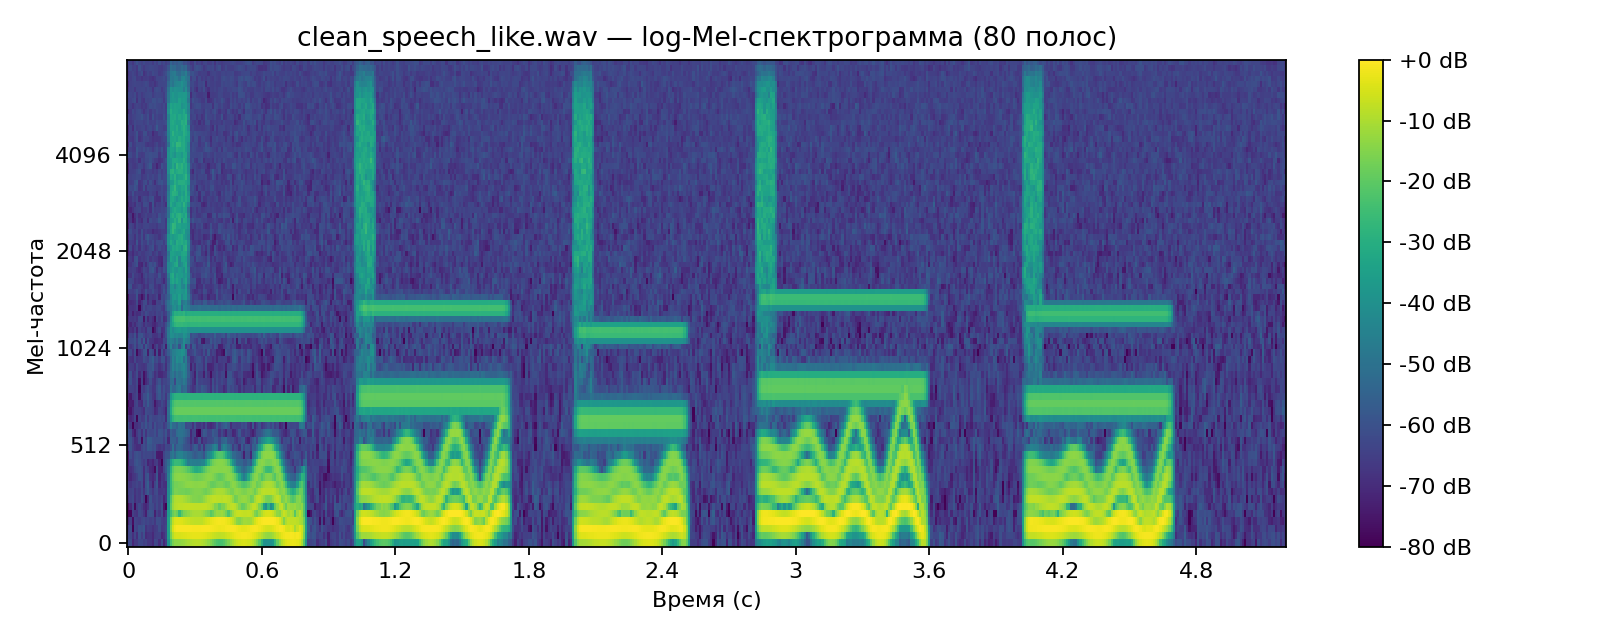

**noisy_speech_like_log_mel.png**

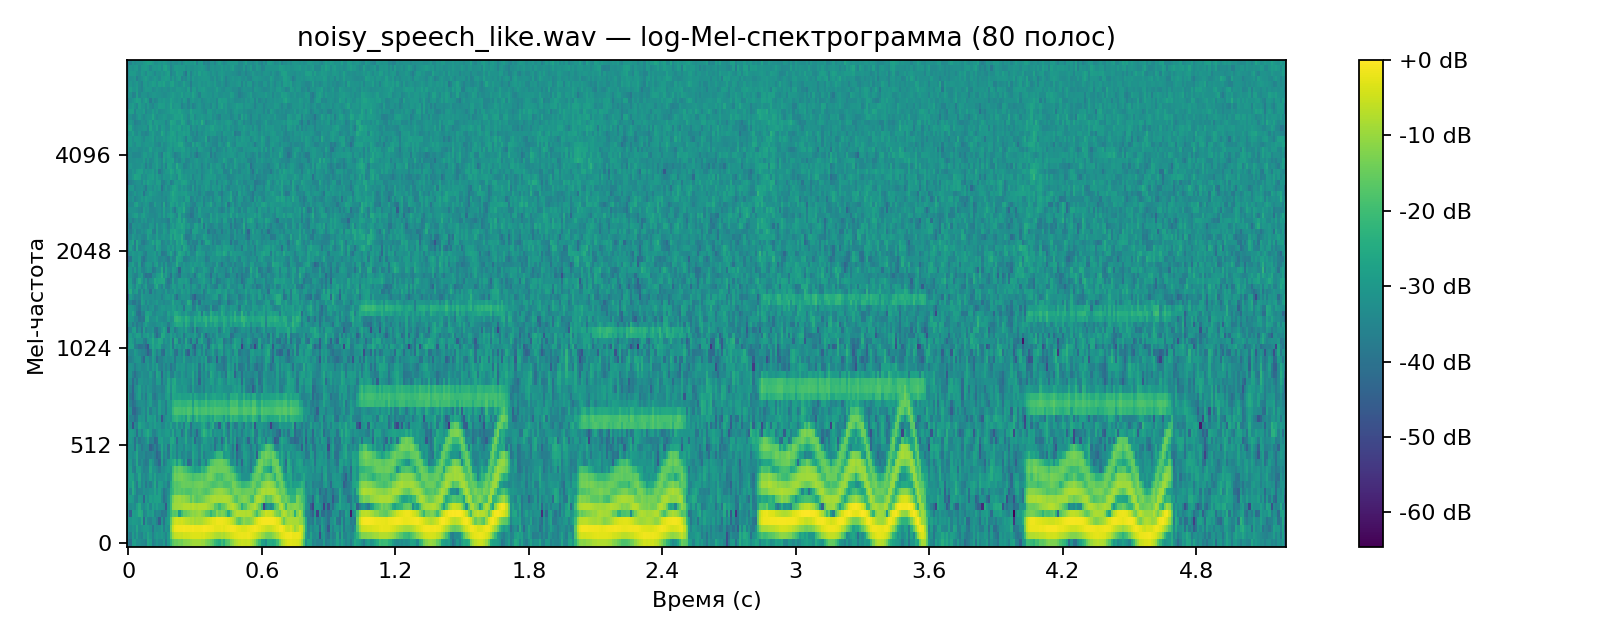

**reverberant_speech_like_log_mel.png**

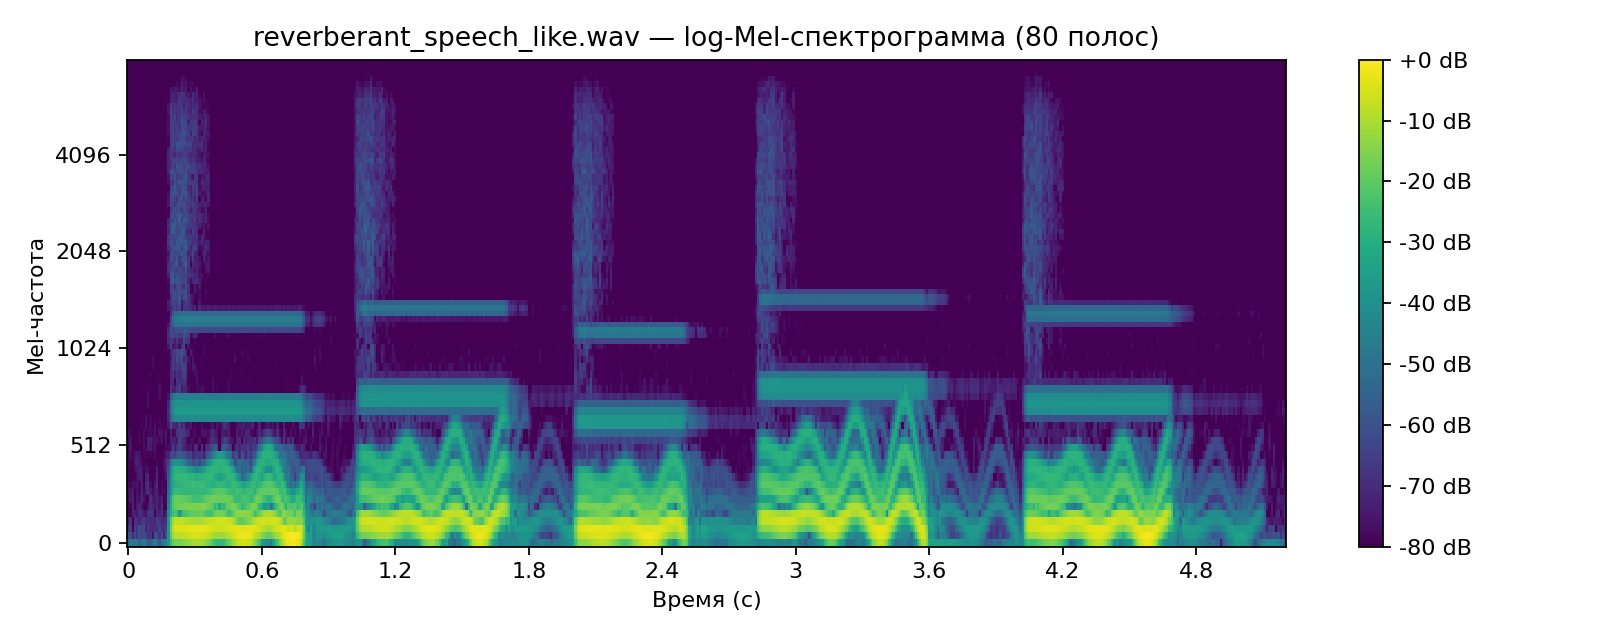

**clipped_speech_like_log_mel.png**

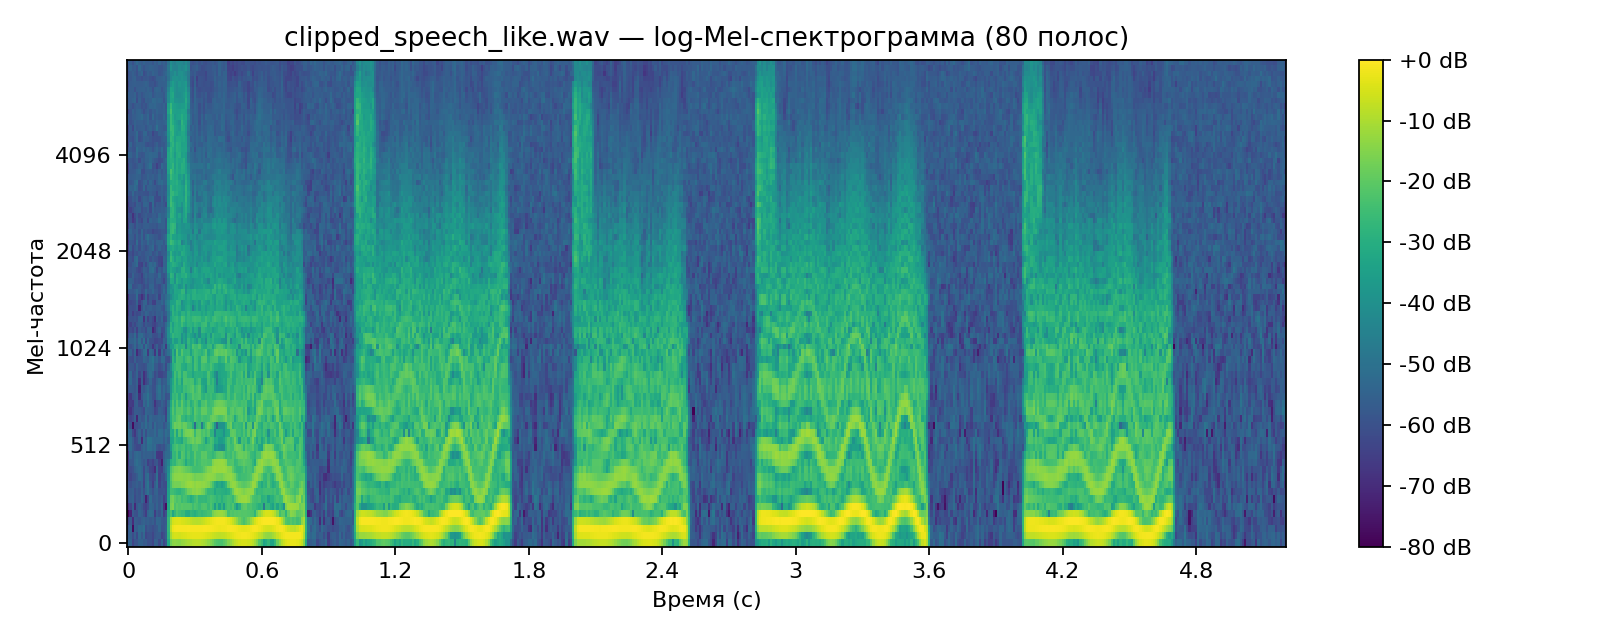

**speed_perturbed_speech_like_log_mel.png**

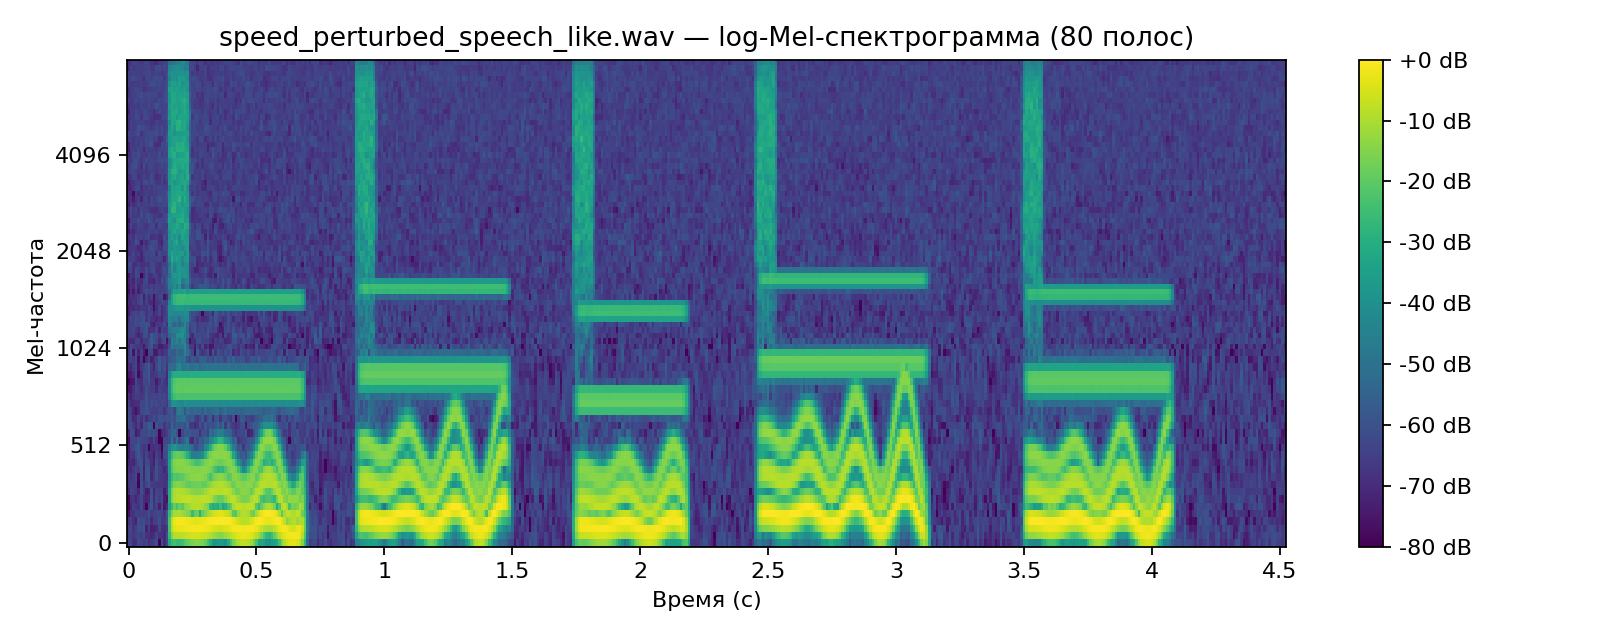

In [7]:
mel_files = [
    "clean_speech_like_log_mel.png",
    "noisy_speech_like_log_mel.png",
    "reverberant_speech_like_log_mel.png",
    "clipped_speech_like_log_mel.png",
    "speed_perturbed_speech_like_log_mel.png",
]

for name in mel_files:
    display(Markdown(f"**{name}**"))
    display(Image(OUT_DIR / name))

Вопросы:

1) Какую информацию легче увидеть на log-Mel, чем на волновой форме?

На log-Mel видна частотная структура речи во времени: гармоники, паузы, искажения. Низкие частоты на log-Mel выглядят детальнее, потому что Mel-шкала растягивает НЧ и сжимает ВЧ.

2) Какая информация теряется или сжимается по сравнению с линейно-частотной STFT?

Теряется частотное разрешение. Mel-фильтры объединяют соседние частоты в полосы. Поэтому вместо частоты в герцах остаётся номер Mel-полосы. На высоких частотах полосы шире, поэтому там детализация ниже. Паузы перестают быть полностью темными. Особенно это заметно там, где энергия сигнала была максимальна (в НЧ).

3) Почему логарифмические энергии полезны для речи?

Логарифмическая шкала сжимает динамический диапазон речи. Тихие и громкие речевые звуки различаются по энергии в тысячи раз, и в линейной шкале тихие звуки из-за этого легко потерять. Логарифм делает и тихие, и громкие детали видимыми одновременно (одновременный учет сильных и слабых амплитуд).

## Часть F — MFCC

MFCC — компактное представление, исторически важное для классического ASR. Даже если современные системы часто используют log-Mel или обучаемые признаки, MFCC остаются полезными для понимания старых пайплайнов и некоторых диагностик.

**clean_speech_like_mfcc.png**

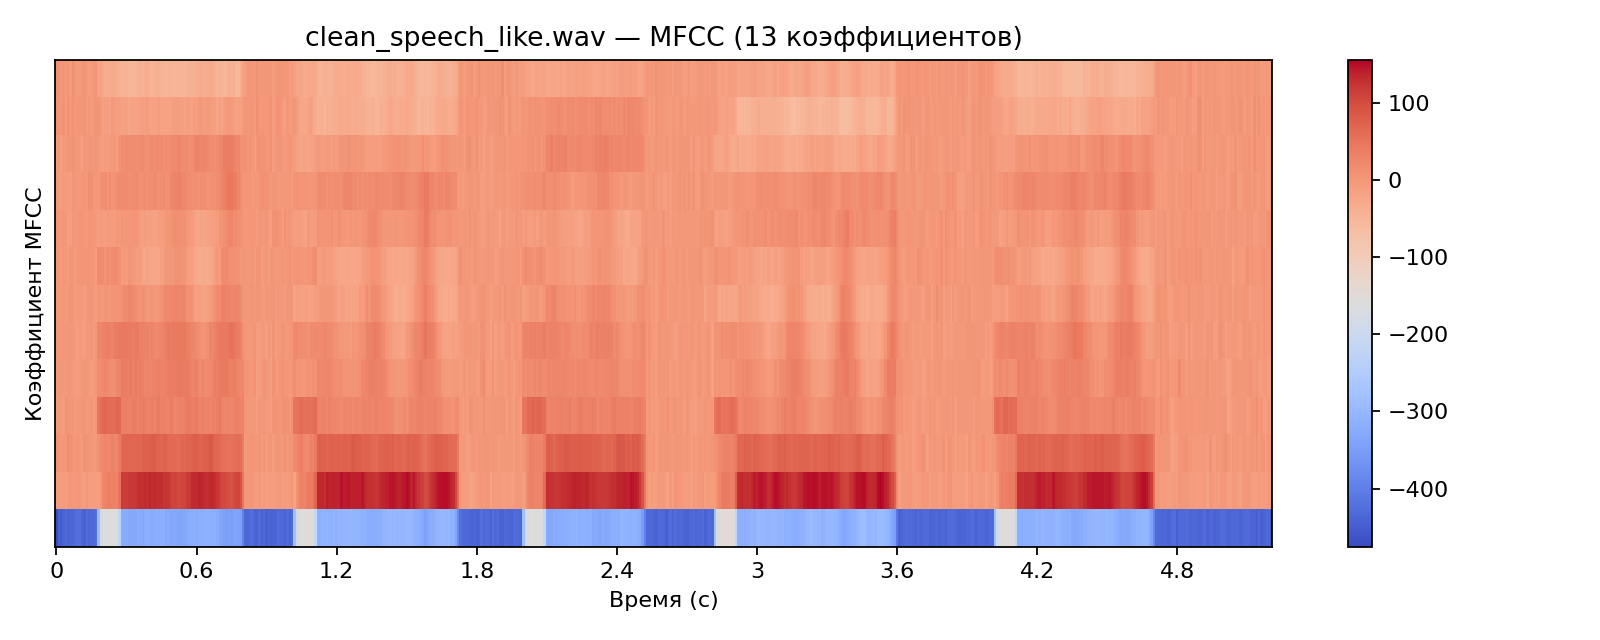

**noisy_speech_like_mfcc.png**

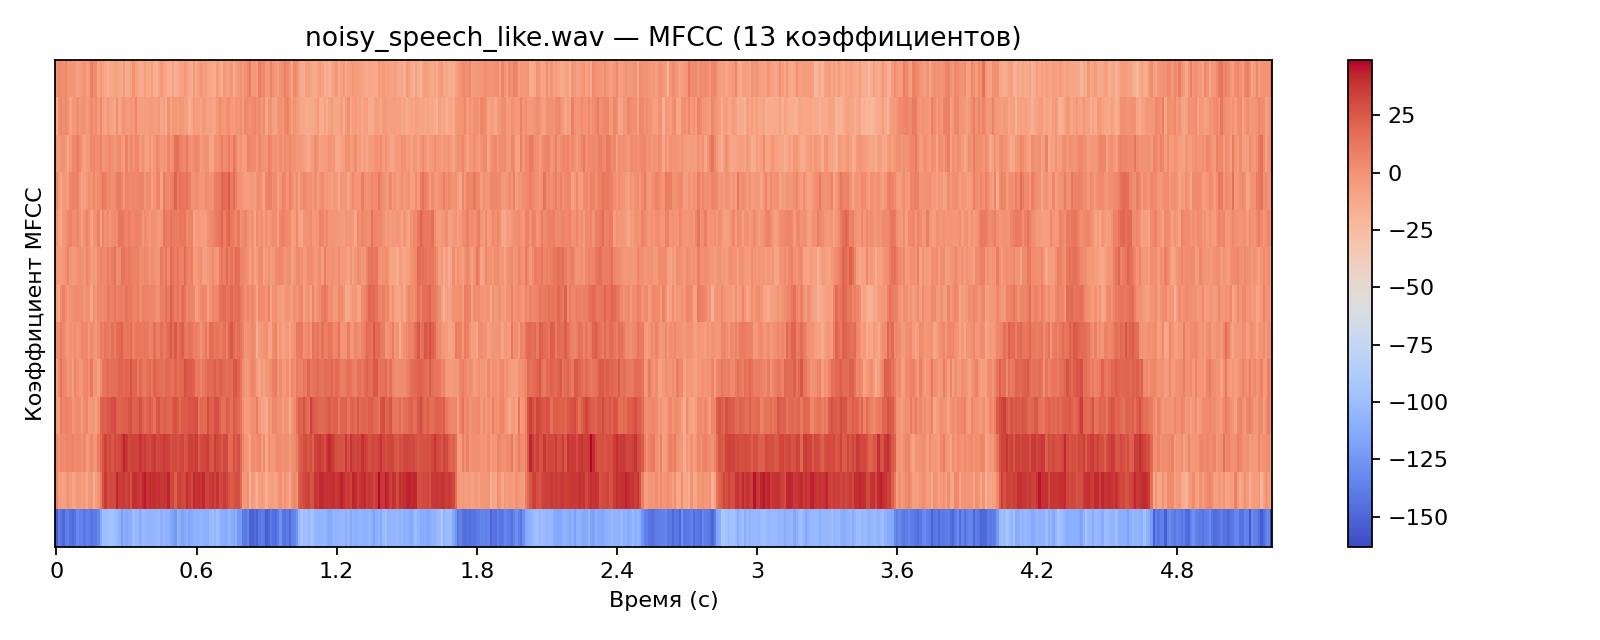

**reverberant_speech_like_mfcc.png**

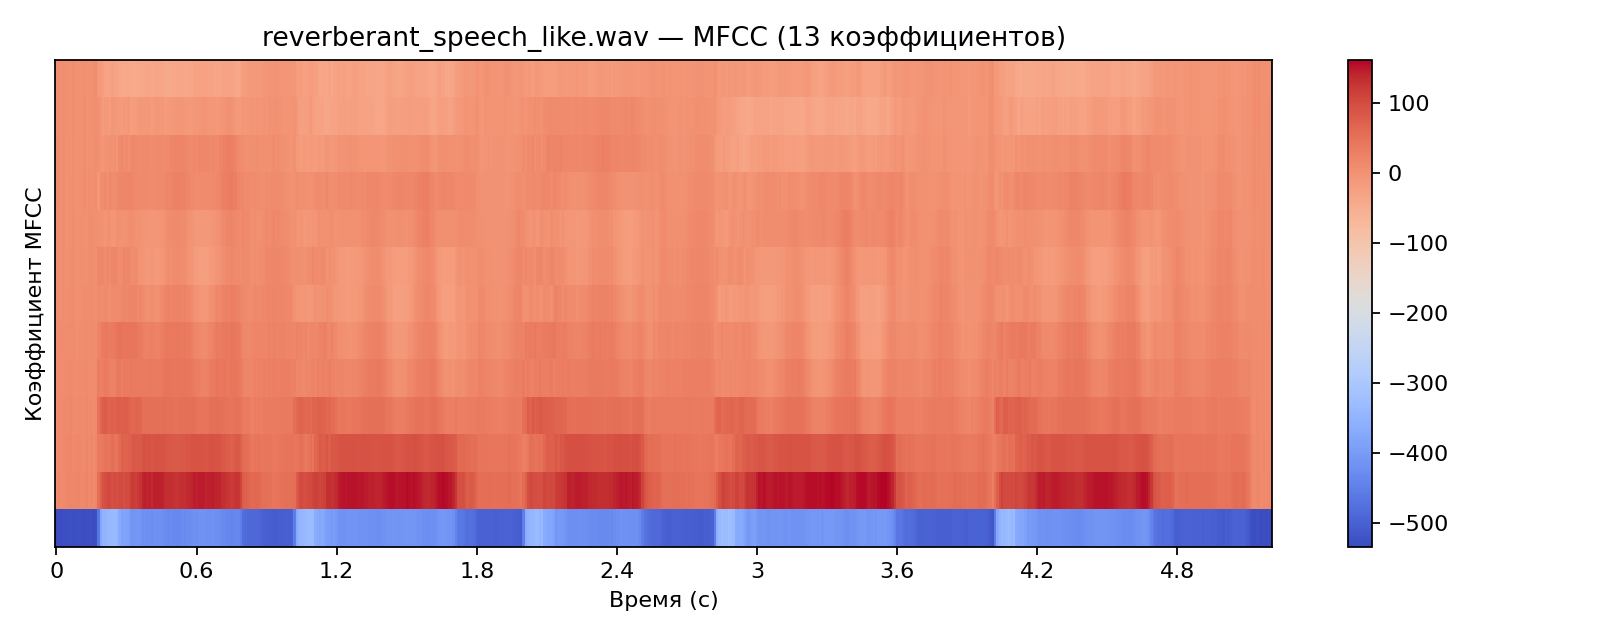

**clipped_speech_like_mfcc.png**

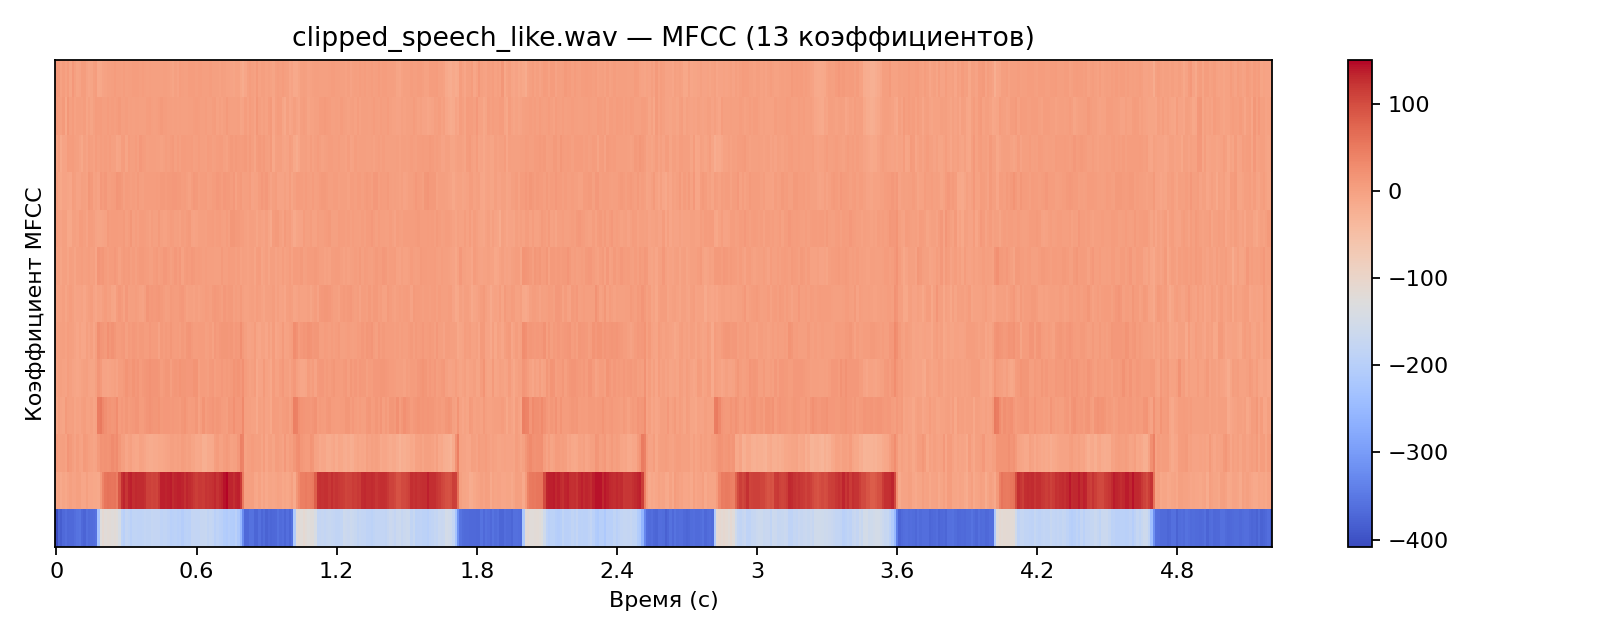

**speed_perturbed_speech_like_mfcc.png**

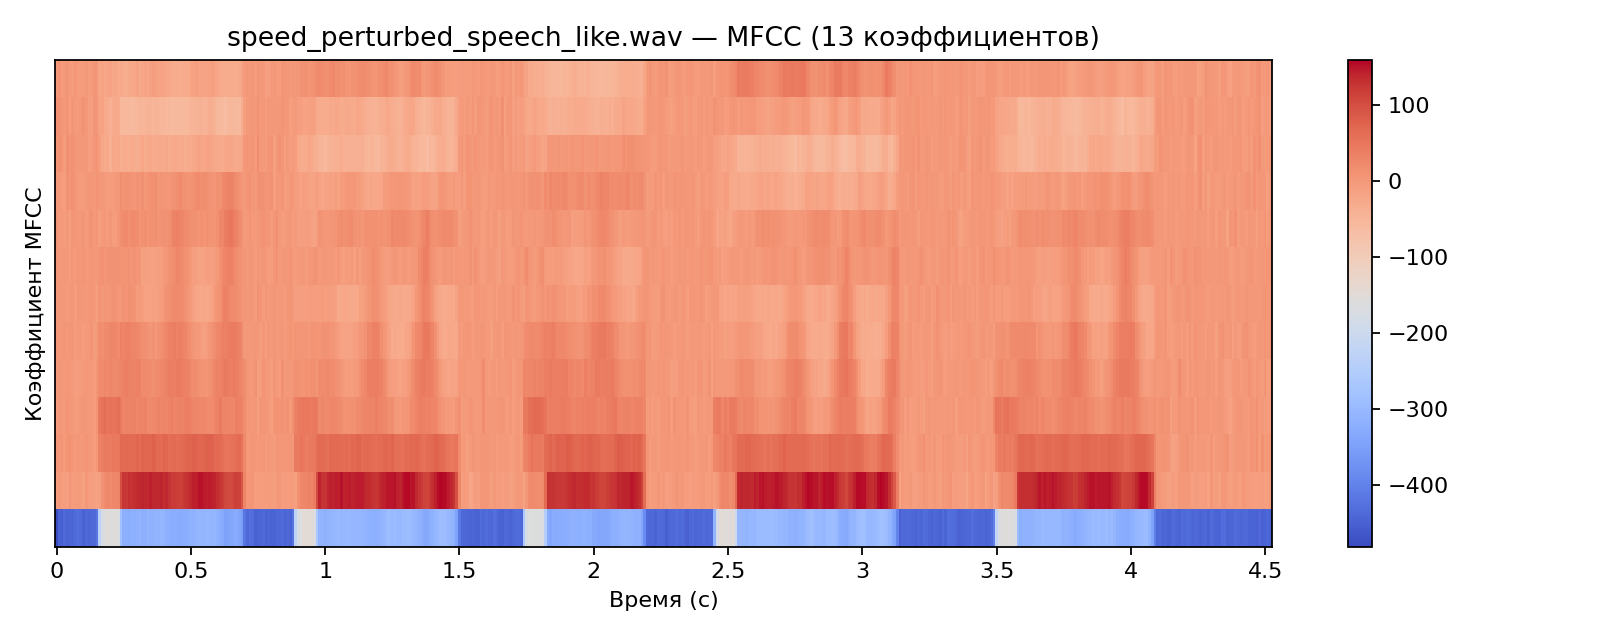

In [8]:
mfcc_files = [
    "clean_speech_like_mfcc.png",
    "noisy_speech_like_mfcc.png",
    "reverberant_speech_like_mfcc.png",
    "clipped_speech_like_mfcc.png",
    "speed_perturbed_speech_like_mfcc.png",
]

for name in mfcc_files:
    display(Markdown(f"**{name}**"))
    display(Image(OUT_DIR / name))

Вопросы:

1) Чем визуально графики MFCC отличаются от log-Mel?

На log-Mel по оси ординат Mel-полосы, то есть частоты, график схож с обычной спектрограммой. На MFCC по оси Y отложены номера 13-ти мел-кепстральных коэффициентов. График менее детальный, вся информация свернута в 13 коэффициентов. Каждый коэффициент отвечает за свою часть звуковой информации (нулевой коэффициент отвечает за среднюю энергию сигнала, первый - за наклон спектральной огибающей, более младшие - за ее форму).

2) Почему компактное представление может быть полезным?

Размерность входа снижается до небольшого набора коэффициентов. Модели нужно меньше параметров и меньше данных для обучения, при этом основная информация о сигнале сохраняется. Для классического ASR компактность критична.

3) Почему современный нейросетевой ASR может предпочитать более богатые log-Mel признаки?

Нейросети умеют сами выделять нужные признаки и не боятся больших размерностей на входе. DCT в MFCC отбрасывает часть информации. Log-Mel сохраняет больше исходной time-frequency структуры, не сворачивает все в весьма ограниченный набор коэффициентов, поэтому в современных энкодерах часто используется.

## Часть G — Сравнить чистое и искажённое аудио

**speed_perturbed_speech_like_mfcc.png**

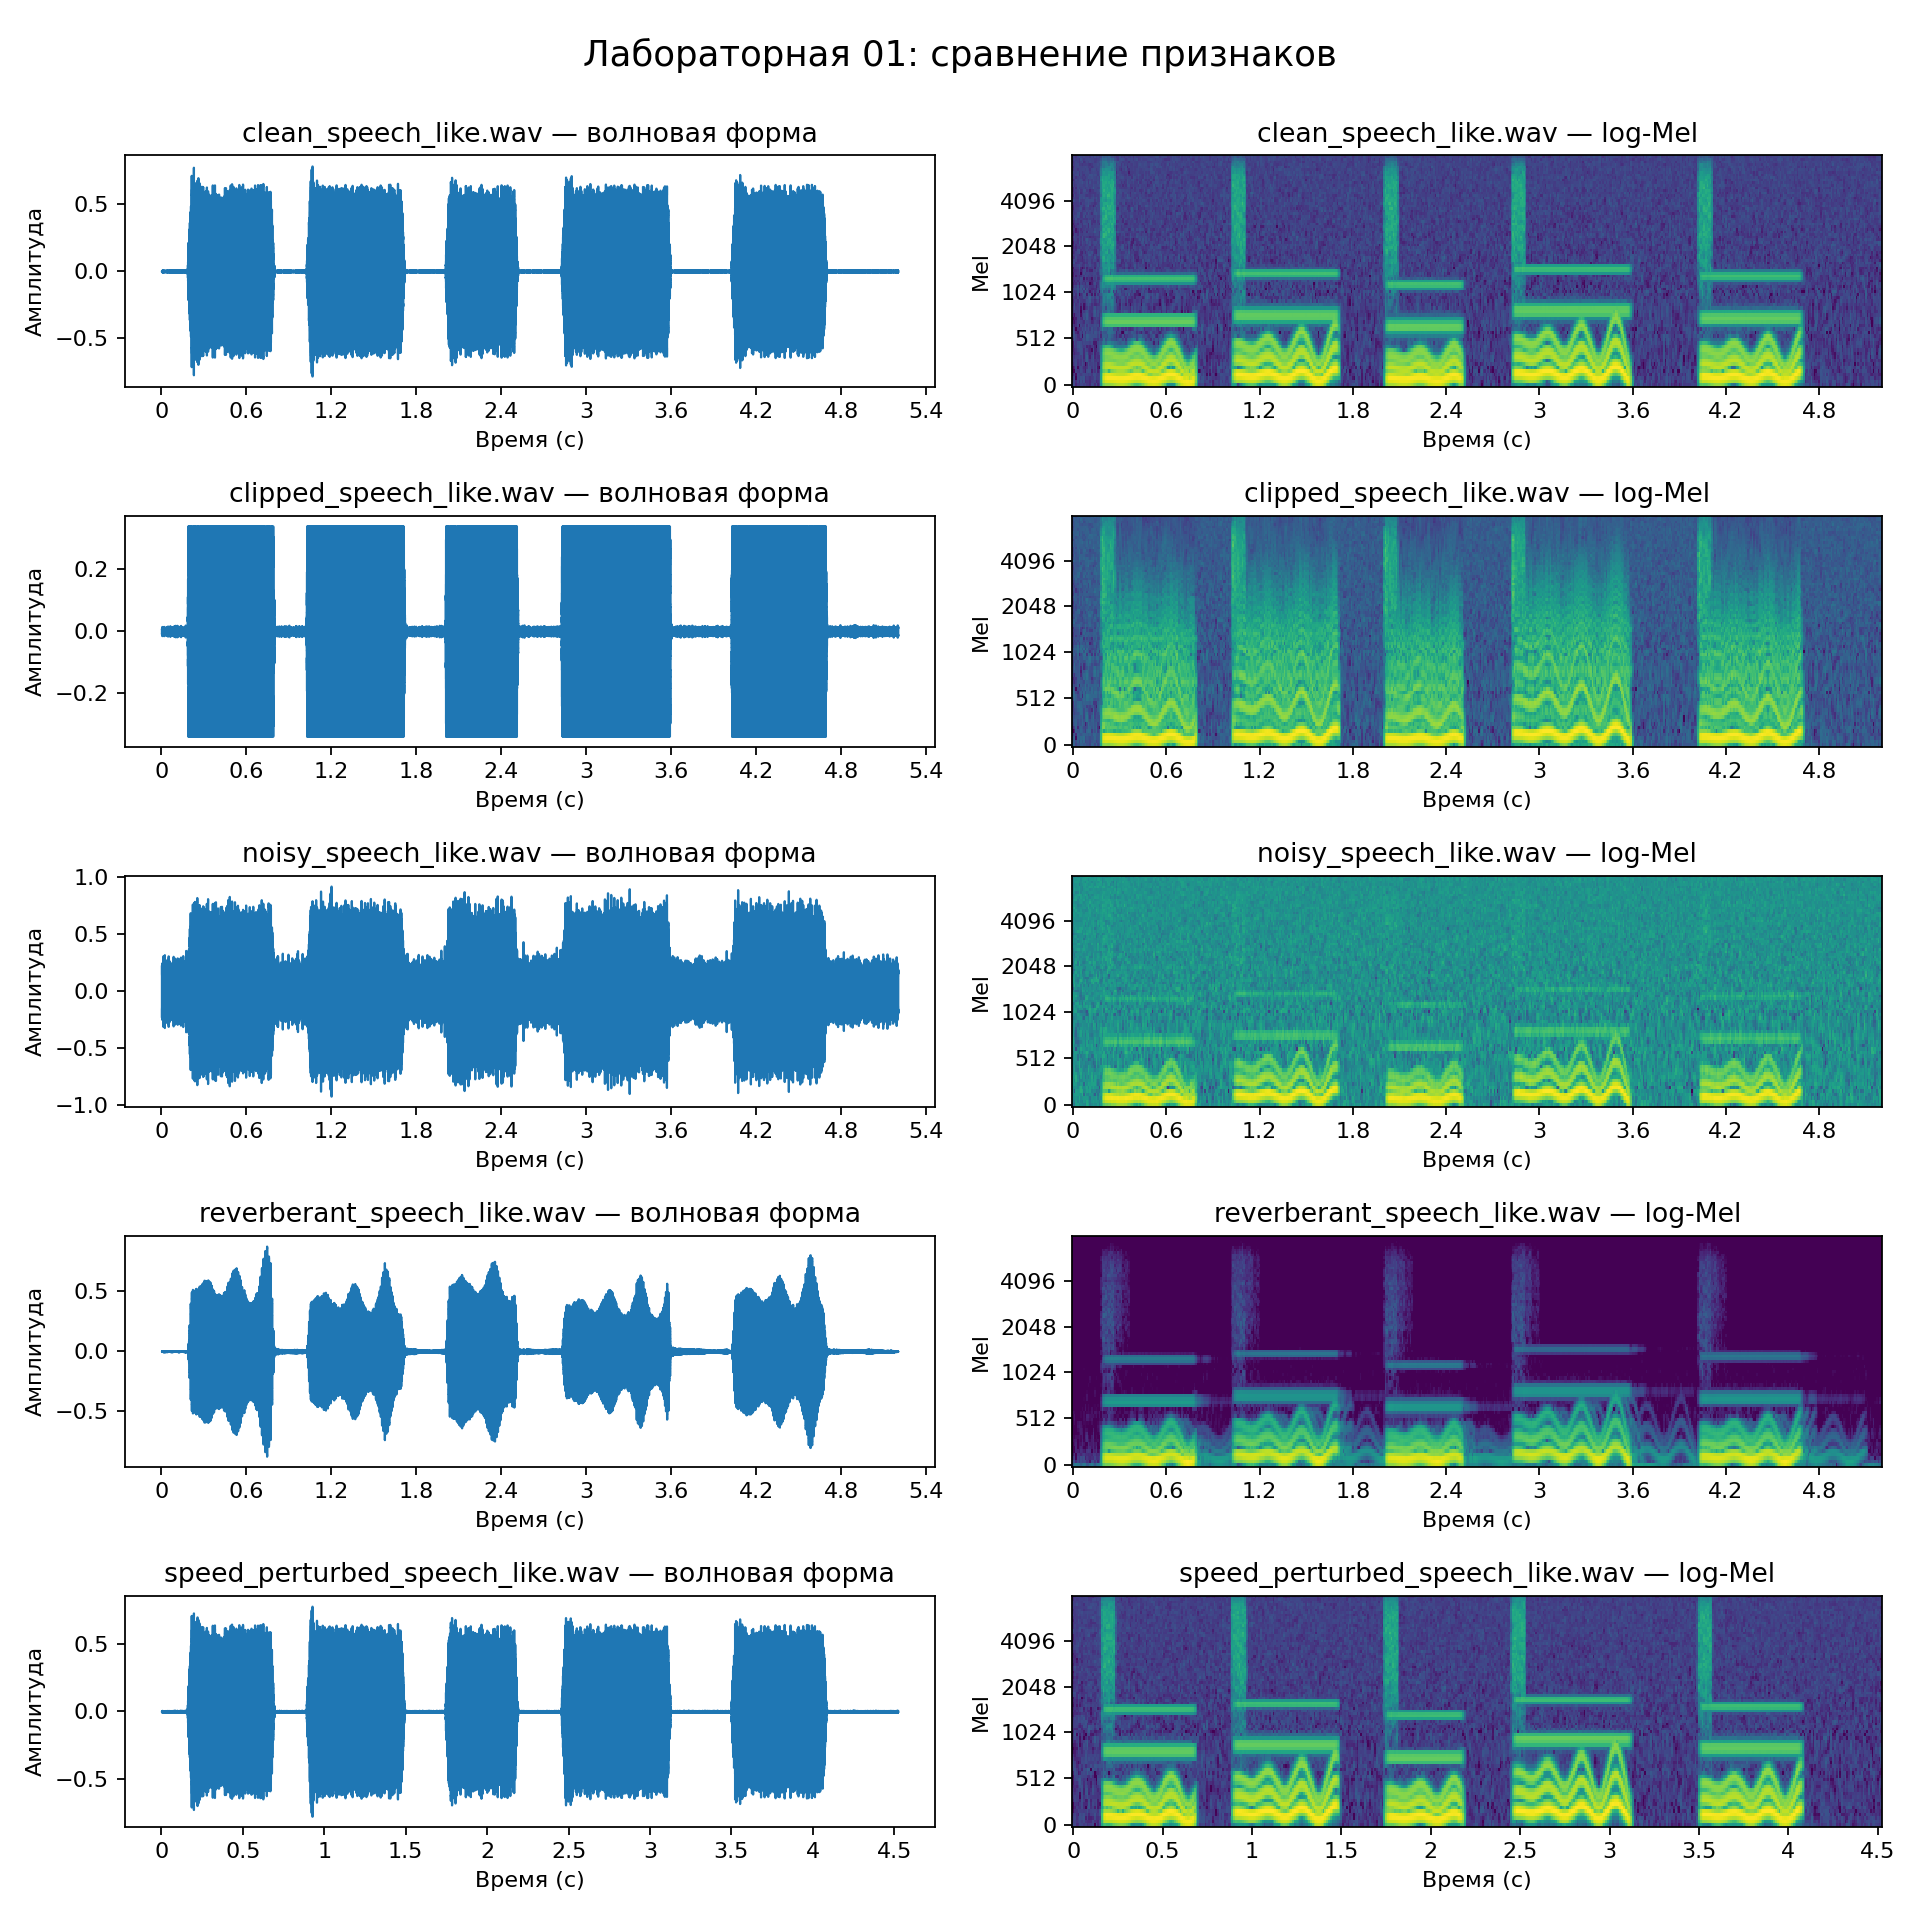

In [9]:
comparison_file = "feature_comparison_contact_sheet.png"

display(Markdown(f"**{name}**"))
display(Image(OUT_DIR / comparison_file))

| Искажение | Что изменилось в волновой форме? | Что изменилось в спектрограмме/log-Mel? | Возможный тип ошибки ASR |
|---|---|---|---|
| Шум |Появились случайные колебания, паузы перестали быть нулевыми |Полезный сигнал плохо различим среди шума (общая энергия сигнала стала выше, паузы перестали выделяться). | замена (модель путает звук с похожим), вставка (принимает шум за речь), удаление(звуки с низкой энергией тонут в шуме), галлюцинация после тишины/шума|
| Реверберация |Огибающая размыта, поэтому визуально подъемы и спады становятся плавнее |Гармоники размыты, границы сегментов смазаны |неверная временная метка (из-за сдвинутых/смазанных границ слов), плохое определение границ речи, замена |
| Клиппинг | Плоские плато ±0.34 вместо пиков |Резкий излом на границе плато приводит к появлению лишних гармоник на высоких частотах |замена (срезанные пики не дают должной информации и форманты путаются), удаление, ухудшение пунктуации/регистра в downstream-обработке (клиппинг искажает интонационную информацию)|
| Ускорение |Структура как в чистом сигнале, но вмещенная в меньший промежуток времени (график короче по оси абсцисс) | Структура как у чистого сигнала, но плотнее по оси времени |неверная временная метка, замена/удаление, если модель обучалась на другом темпе речи |

Типы ошибок ASR:

- удаление;
- замена;
- вставка;
- неверная временная метка;
- плохое определение границ речи;
- галлюцинация после тишины/шума;
- ухудшение пунктуации/регистра в downstream-обработке.

## Запись

In [ ]:
name = "Recording_1.wav"
audio, sr = librosa.load(f"data/wav/{name}", sr=16000, mono=True)

display(Markdown(f"**{name}** — {len(audio)/sr:.2f}с, sr={sr}, peak={abs(audio).max():.3f}"))
display(Audio(audio, rate=sr))

**Recording_1.wav** — 6.00с, sr=16000, peak=0.375

In [36]:
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

summary = pd.read_csv(OUT_DIR / "audio_summary.csv")
summary

,filename,sample_rate_hz,duration_s,num_samples,peak_amplitude,rms,silence_fraction,clipping_fraction
0,Recording_1.wav,16000,6.000,96000,0.375336,0.062055,0.529875,0.000021
1,clean_speech_like.wav,16000,5.200,83200,0.780029,0.250151,0.388930,0.000024
2,clipped_speech_like.wav,16000,5.200,83200,0.340027,0.245213,0.298690,0.463798
3,noisy_speech_like.wav,16000,5.200,83200,0.920013,0.265441,0.077200,0.000012
4,reverberant_speech_like.wav,16000,5.200,83200,0.880005,0.216411,0.385096,0.000108
5,speed_perturbed_speech_like.wav,16000,4.522,72348,0.780029,0.250186,0.389244,0.000014


### Waveform

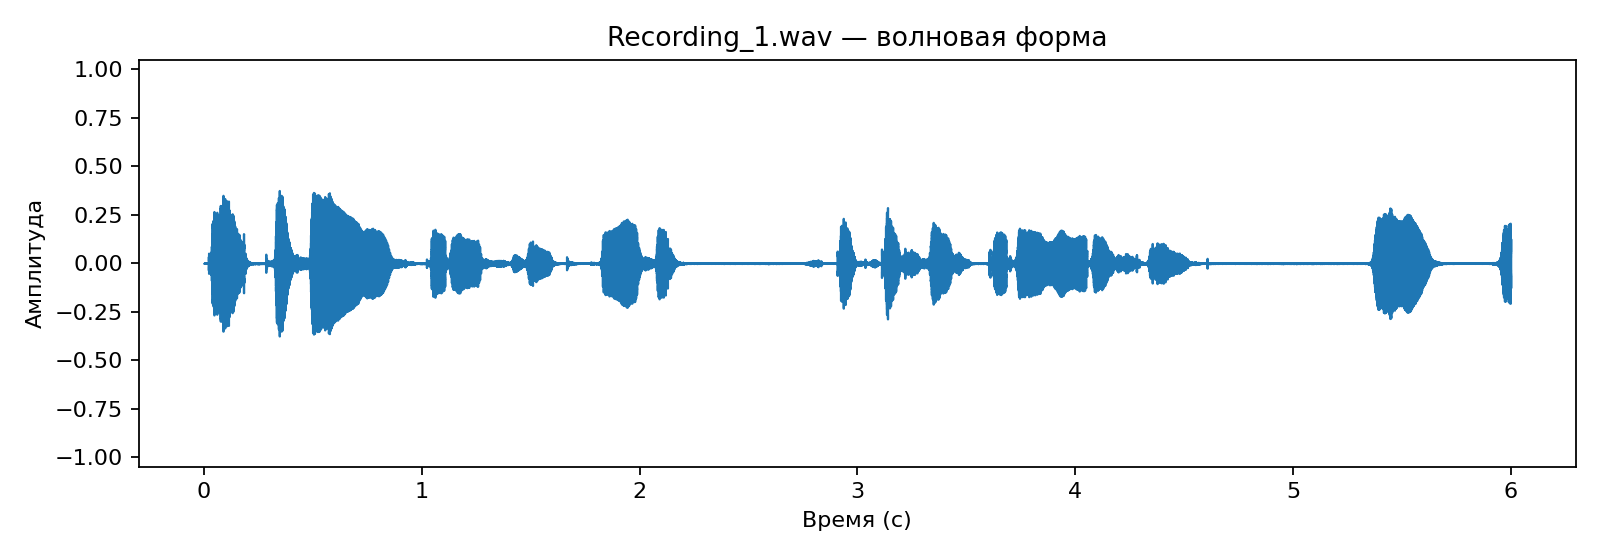

### Waveform (zoom)

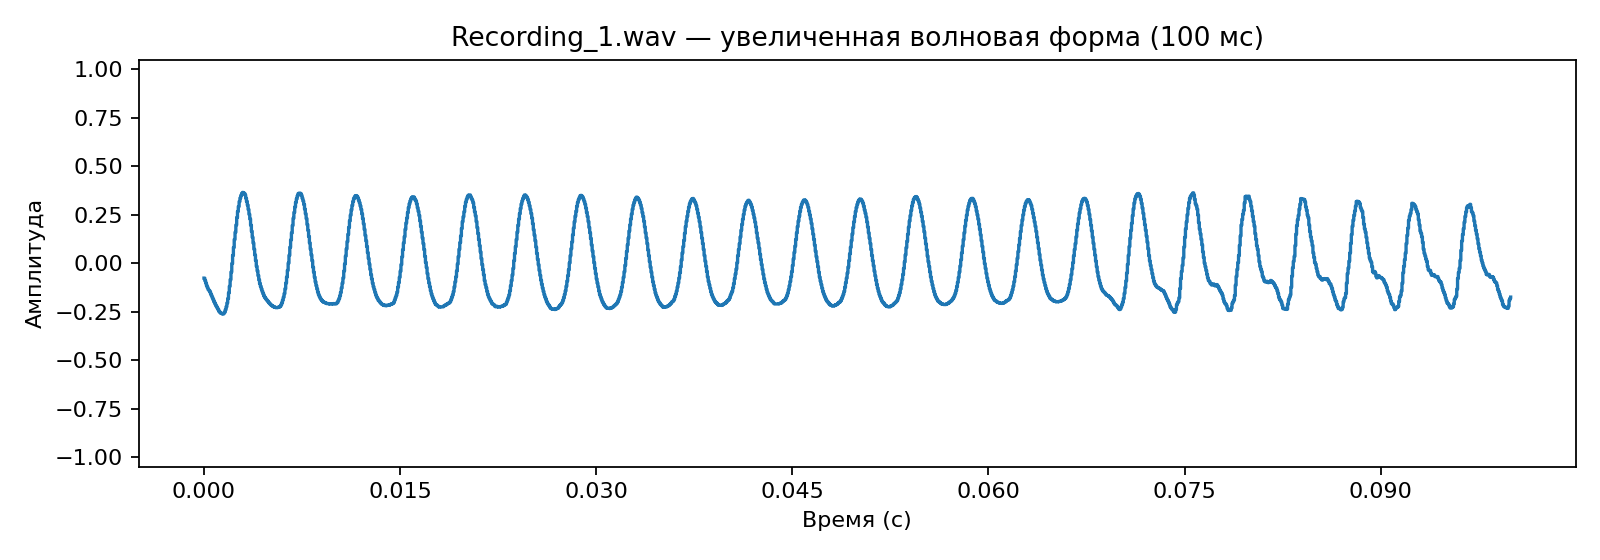

### STFT-спектрограмма

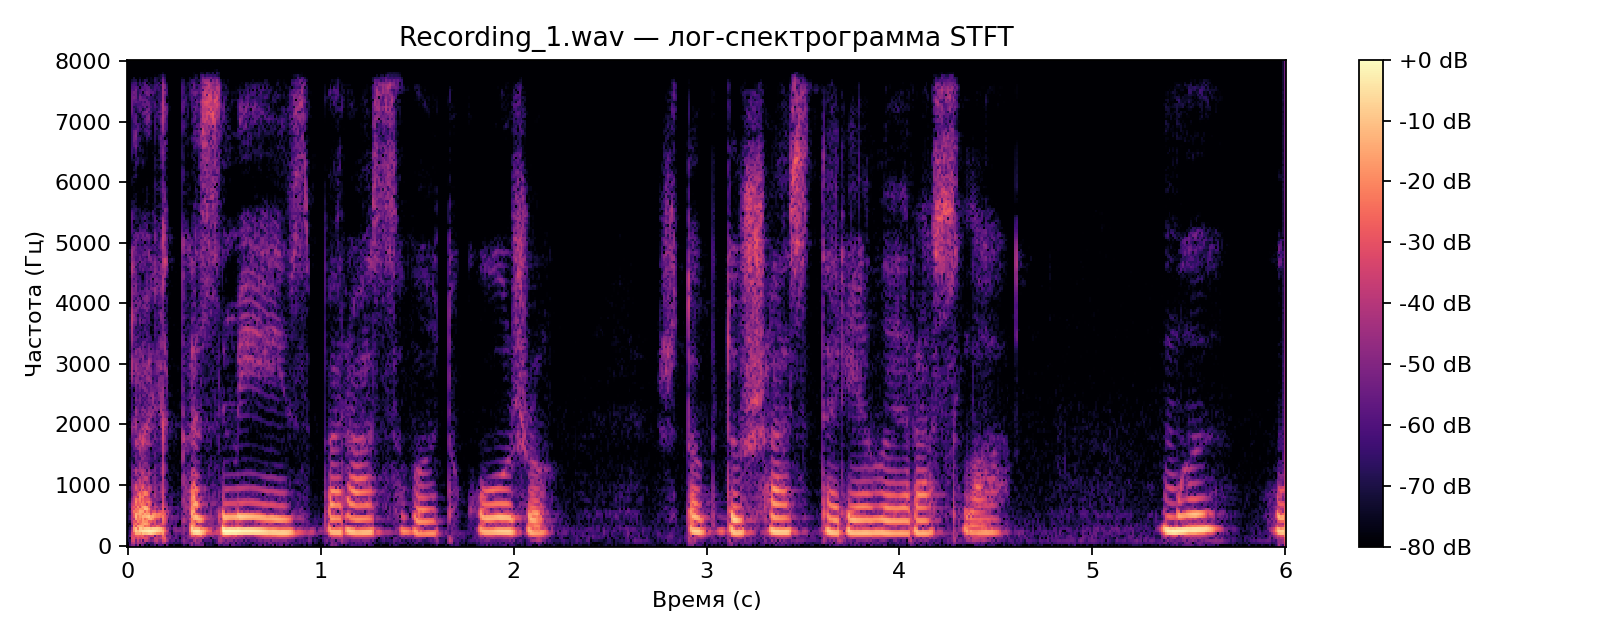

### Log-Mel

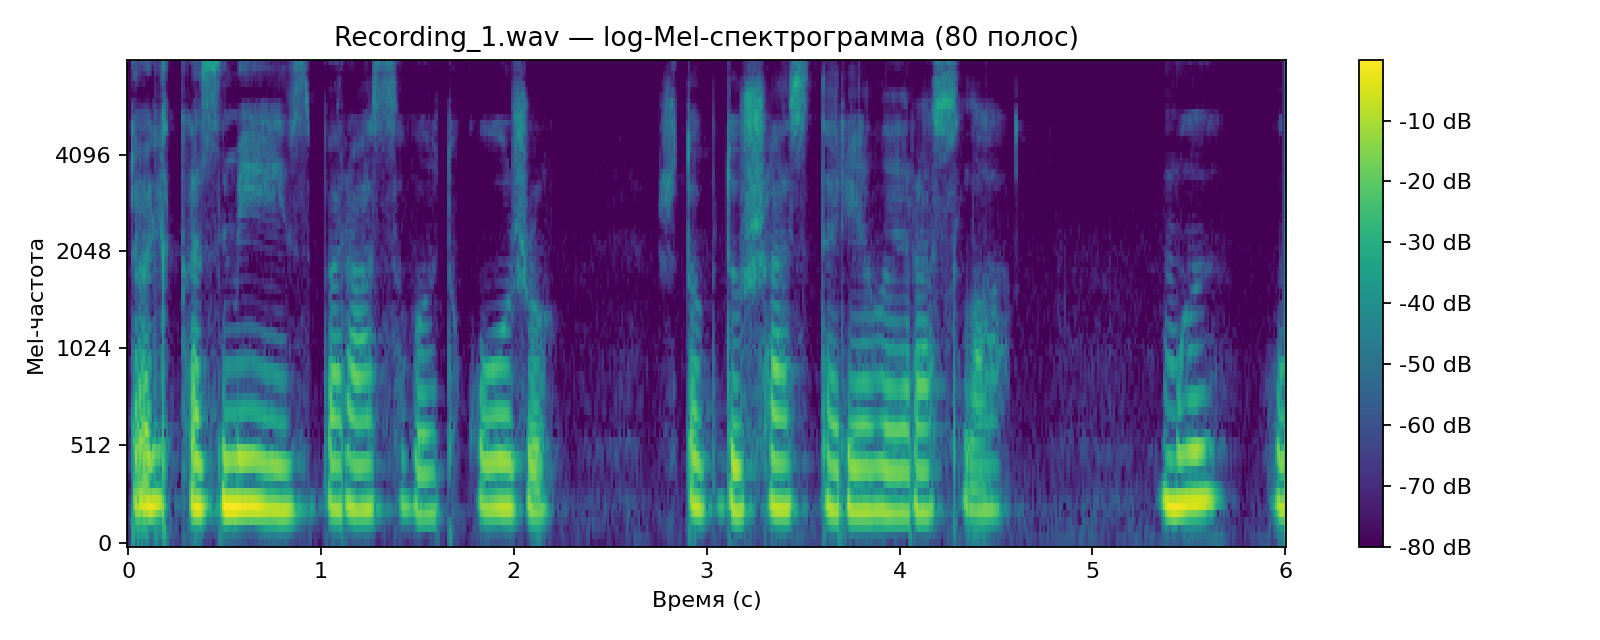

### MFCC

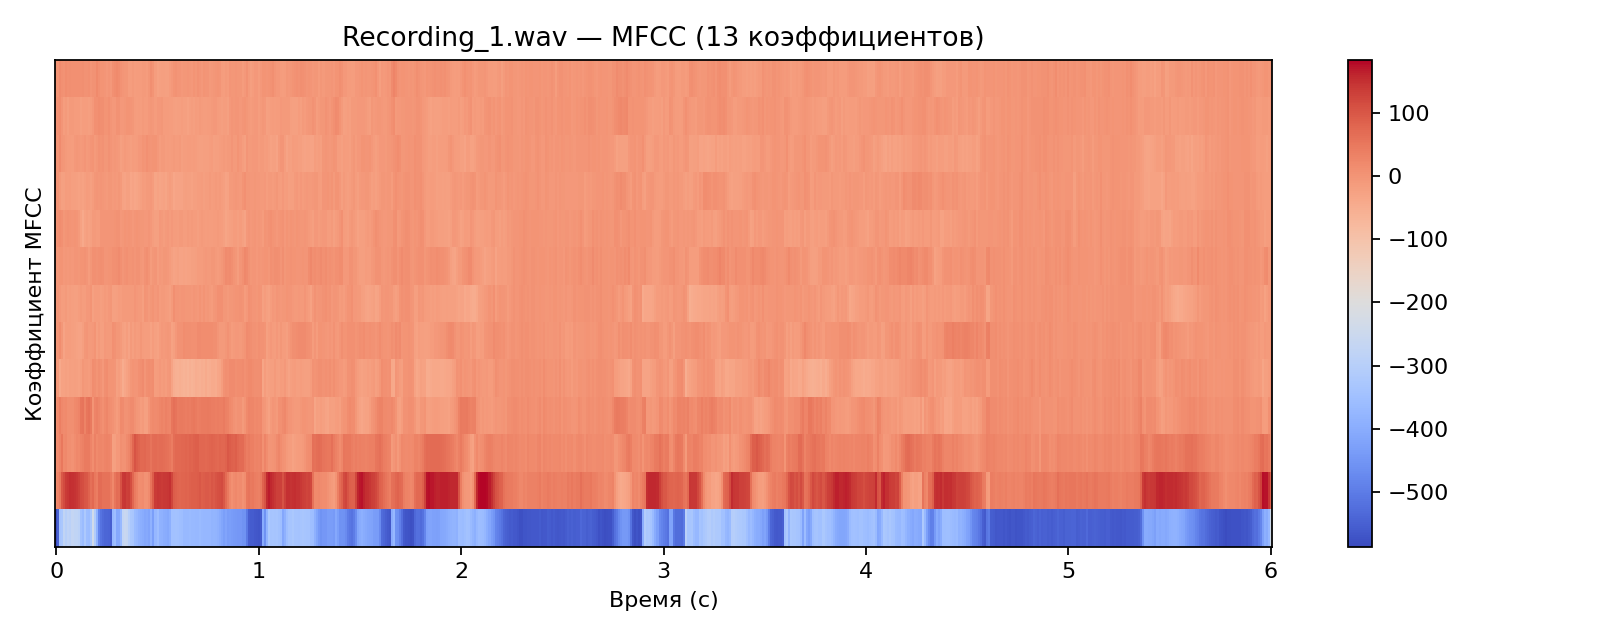

In [48]:
for suffix, title in [
    ("waveform", "Waveform"),
    ("waveform_zoom", "Waveform (zoom)"),
    ("stft_spectrogram", "STFT-спектрограмма"),
    ("log_mel", "Log-Mel"),
    ("mfcc", "MFCC"),
]:
    p = OUT_DIR / f"Recording_1_{suffix}.png"
    display(Markdown(f"### {title}"))
    display(Image(filename=str(p)))

## Сравнение Recording_1.wav со сгенерированными примерами

Анализ графиков

- **Waveform:** плавная огибающая, плато отсутствуют (нет клиппинга); видны длинные паузы.
- **Waveform (zoom):** почти периодические колебания на частоте около 230 Гц отражают основной тон голоса.
- **STFT:** чёткие горизонтальные гармоники, паузы тёмные, слабая зашумленность.
- **Log-Mel:** энергия в основном сосредоточена в НЧ (до 2 кГц), границы сегментов достаточно резкие.
- **MFCC:** c0 и c1 чётко реагируют на речь (яркие); в паузах все коэффициенты бледнеют, но не обнуляются из-за микрофонного шума.

**Больше всего `Recording_1.wav` похож на `clean_speech_like.wav`**, поскольку отсутствует клиппинг, видны достаточно чёткие гармоники на спектрограмме, тёмные четкие паузы. В записи много пауз и мало RMS, что свидетельствует о меньшей громкости звука.

### Вывод

Живая речь менее стационарна (амплитуда и форма меняются от слога к слогу), но по чёткости спектрограммы запись ближе к чистому, чем к искажённым примерам. Слабый фоновый шум присутствует, но не мешает анализу.